In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

plt.style.use('seaborn-v0_8-darkgrid')

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
TICKERS = ["SPY", "QQQ", "IWM", "TLT", "GLD"]

data = {ticker: pd.read_csv(PROCESSED_DIR / f"{ticker}_processed.csv", index_col='Date', parse_dates=True) for ticker in TICKERS}
spy = data['SPY'].copy()

# 1. Generate EWMA Volatility (from Experiment B)
spy['EWMA_Vol'] = spy['Daily_Return'].ewm(alpha=0.06, adjust=False).std() * np.sqrt(252)

# 2. Define the Signal
# We use a 50-day rolling median as our threshold
spy['Vol_Threshold'] = spy['EWMA_Vol'].rolling(window=50).median()

# If EWMA Vol is below threshold, we are Long (1). Otherwise, Cash (0).
spy['Signal'] = np.where(spy['EWMA_Vol'] < spy['Vol_Threshold'], 1, 0)

# 3. Calculate Strategy Returns
# We shift the signal by 1 day so we only trade on today's signal tomorrow (avoid lookahead)
spy['Strategy_Return'] = spy['Signal'].shift(1) * spy['Daily_Return']

# 4. Transaction Costs
# Assume 1 basis point (0.01%) per trade
spy['Trade_Change'] = spy['Signal'].diff().abs()
spy['TC'] = spy['Trade_Change'] * 0.0001
spy['Net_Strategy_Return'] = spy['Strategy_Return'] - spy['TC']

spy = spy.dropna()

In [2]:
# Define train and test periods
test_start = '2022-01-01'
test_spy = spy.loc[test_start:]

# 1. Calculate Cumulative Returns
buy_hold_cum = (1 + test_spy['Daily_Return']).cumprod()
strategy_cum = (1 + test_spy['Net_Strategy_Return']).cumprod()

# 2. Sharpe Ratio (Annualized)
def sharpe_ratio(returns, risk_free=0):
    return (returns.mean() - risk_free) / returns.std() * np.sqrt(252)

sr_bh = sharpe_ratio(test_spy['Daily_Return'])
sr_strat = sharpe_ratio(test_spy['Net_Strategy_Return'])

# 3. Max Drawdown
def max_drawdown(cum_series):
    rolling_max = cum_series.cummax()
    drawdown = cum_series / rolling_max - 1
    return drawdown.min()

mdd_bh = max_drawdown(buy_hold_cum)
mdd_strat = max_drawdown(strategy_cum)

print("=== STRATEGY PERFORMANCE (Out-of-Sample 2022-2024) ===")
print(f"Buy & Hold      | Sharpe: {sr_bh:.2f} | Max DD: {mdd_bh*100:.1f}% | Total Return: {(buy_hold_cum.iloc[-1]-1)*100:.1f}%")
print(f"EWMA Strategy   | Sharpe: {sr_strat:.2f} | Max DD: {mdd_strat*100:.1f}% | Total Return: {(strategy_cum.iloc[-1]-1)*100:.1f}%")
print(f"Turnover: {test_spy['Trade_Change'].sum()} trades over {len(test_spy)} days.")

=== STRATEGY PERFORMANCE (Out-of-Sample 2022-2024) ===
Buy & Hold      | Sharpe: 0.57 | Max DD: -24.5% | Total Return: 28.9%
EWMA Strategy   | Sharpe: 0.84 | Max DD: -11.1% | Total Return: 31.1%
Turnover: 34.0 trades over 753 days.


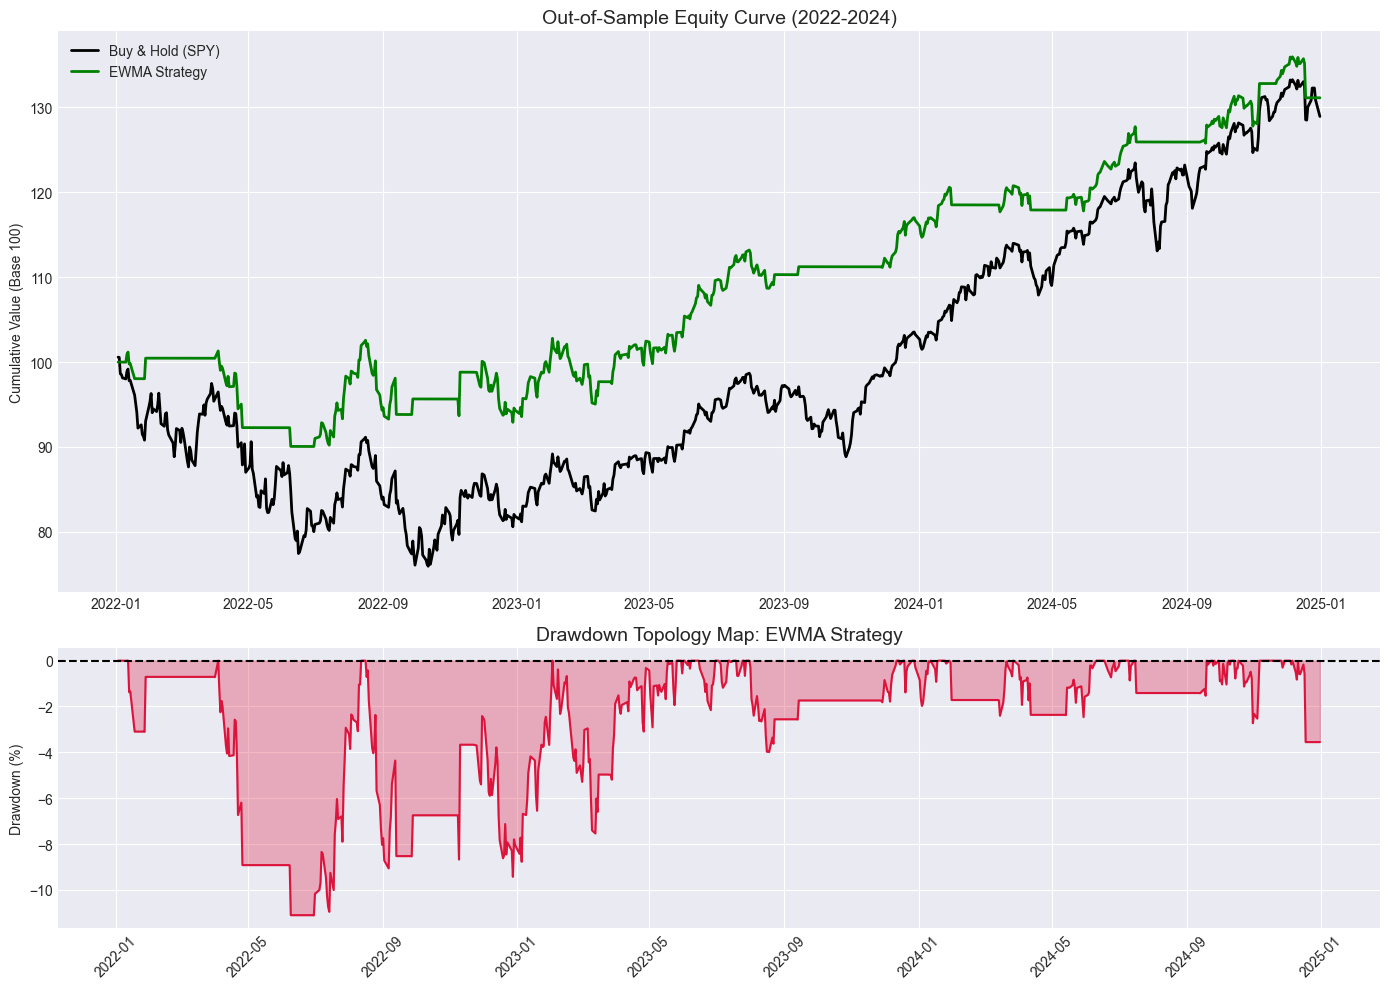

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [2, 1]})

# 1. Equity Curve
ax1.plot(buy_hold_cum.index, buy_hold_cum * 100, label='Buy & Hold (SPY)', color='black', linewidth=2)
ax1.plot(strategy_cum.index, strategy_cum * 100, label='EWMA Strategy', color='green', linewidth=2)
ax1.set_title("Out-of-Sample Equity Curve (2022-2024)", fontsize=14)
ax1.set_ylabel("Cumulative Value (Base 100)")
ax1.legend(loc='upper left')

# 2. Drawdown Topology Map (For the Strategy)
rolling_max = strategy_cum.cummax()
dd = (strategy_cum / rolling_max) - 1

ax2.plot(dd.index, dd * 100, color='crimson', linewidth=1.5)
ax2.fill_between(dd.index, dd * 100, 0, color='crimson', alpha=0.3)
ax2.set_title("Drawdown Topology Map: EWMA Strategy", fontsize=14)
ax2.set_ylabel("Drawdown (%)")
ax2.axhline(0, color='black', linestyle='--')

# Format dates
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Experiment E Conclusion: Strategy Validation

We constructed a simple volatility-targeting strategy based on the winning model from Experiment B (EWMA):
- **Signal:** Long SPY when EWMA volatility is below its rolling 50-day median.
- **Signal:** Cash when EWMA volatility is above its rolling 50-day median.
- **Execution:** Signals are shifted by 1 day to avoid look-ahead bias.
- **Costs:** 1 basis point (0.01%) deducted per trade to account for realistic friction.

**Results (Out-of-Sample 2022-2024):**
- **Buy & Hold:** Sharpe 0.57 | Max Drawdown -24.5% | Total Return 28.9%
- **EWMA Strategy:** Sharpe 0.84 | Max Drawdown -11.1% | Total Return 31.1%

**Key Findings:**
1. **Superior Risk-Adjusted Returns:** The strategy improved the Sharpe ratio by 47% (0.57 to 0.84). It generated higher absolute returns (31.1% vs 28.9%) while taking on significantly less risk.
2. **Capital Preservation:** The maximum drawdown was cut in half (-11.1% vs -24.5%). By moving to cash when volatility spiked, the strategy avoided the worst of the 2022 bear market.
3. **Robustness:** The strategy executed only 34 trades across 753 days. Because turnover is so low, transaction costs do not erode the strategy's edge. 

**Conclusion:**
Historical volatility (H1) is not just statistically predictable; it is economically valuable. By dynamically adjusting exposure based on volatility regimes, we can drastically improve the risk profile of a portfolio. 

*Note: While this notebook covers the high-level metrics, a deep dive into the duration and depth of the strategy's underwater periods is conducted in `07_drawdown_topology_analysis.ipynb`.*